# Scenario

#### You've been hired by the New York Division of Transportation as a Data Analyst with the primary goal of improving the efficiency and reliability of the city's bus transportation system.
#### The city has been experiencing a significant number of bus breakdowns and delays, which has been causing inconvenience to commuters and straining the city's public transportation resources.
#### Your task is to analyze the provided data to identify patterns and factors that contribute to these breakdowns and delays. 

# Importing libraries

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import re

In [3]:
# Reading a file

In [5]:
Bus=pd.read_excel(r'C:\Users\Sizwe\OneDrive - Durban University of Technology\Desktop\Data analysis\My projects\Pandas project 3(excel)--NYC Transportation\Bus_Breakdown_and_Delays_NYC Project.xlsx',sheet_name='Bus_Breakdown_and_Delays_NYC')
Bus.head()

,School_Year,Busbreakdown_ID,Run_Type,Bus_No,Route_Number,Reason,Schools_Serviced,Occurred_On,Created_On,Boro,...,How_Long_Delayed,Number_Of_Students_On_The_Bus,Has_Contractor_Notified_Schools,Has_Contractor_Notified_Parents,Have_You_Alerted_OPT,Informed_On,Incident_Number,Last_Updated_On,Breakdown_or_Running_Late,School_Age_or_PreK
0,2022-2023,1736720,Special Ed AM Run,21017,M772,Mechanical Problem,601006427,2022-09-01 06:50:00,2022-09-01 07:29:00,Manhattan,...,NaN,0.0,No,No,No,2022-09-01 07:29:00,NaN,1900-01-01,Breakdown,School-Age
1,2022-2023,1736736,Special Ed AM Run,20027,N729,Heavy Traffic,75907,2022-09-01 08:05:00,2022-09-01 08:31:00,Nassau County,...,46-60 Min,3.0,Yes,Yes,No,2022-09-01 08:31:00,NaN,1900-01-01,Running Late,School-Age
2,2022-2023,1736748,Special Ed AM Run,244,W203,Heavy Traffic,75871,2022-09-02 06:11:00,2022-09-02 06:14:00,Westchester,...,0-15 Min,0.0,Yes,Yes,Yes,2022-09-02 06:14:00,NaN,1900-01-01,Running Late,School-Age
3,2022-2023,1736765,Special Ed AM Run,10436,W501,Heavy Traffic,75615,2022-09-06 05:50:00,2022-09-06 05:57:00,Westchester,...,31-45 Min,0.0,No,Yes,No,2022-09-06 05:57:00,NaN,1900-01-01,Running Late,School-Age
4,2022-2023,1736837,Pre-K/EI,110,3,Heavy Traffic,C530,2022-09-06 08:12:00,2022-09-06 08:14:00,Bronx,...,16-30 Min,3.0,Yes,Yes,No,2022-09-06 08:14:00,NaN,1900-01-01,Running Late,Pre-K


#### Questions for the project

In [8]:
# 1.What are the most common reasons for delays and breakdowns?
# 2.How do delay times vary by bus company and borough?
# 3.Is there a correlation between specific days of the week and the frequency of breakdowns or delays?
# 4.Are certain bus routes more prone to breakdowns or delays than others?
# 5.Is there a relationship between the number of students on the bus and the likelihood or severity of a delay or breakdown?
# 6.Do contractor notifications (to schools, parents, or OPT) affect how long delays last?

#### Columns to be used

In [11]:
# 1.Busbreakdown_ID, Reason,How_Long_Delayed
# 2.How_Long_Delayed--strip,Bus_Company_Name,Boro
# 3.Occurred_On,How_Long_Delayed,Breakdown_or_Running_Late(split),Route_Number
# 4.Route_Number,Reason
# 5. Number_Of_Students_On_The_Bus, How_Long_Delayed and Breakdown_or_Running_Late.
# 6.Has_Contractor_Notified_Schools, Has_Contractor_Notified_Parents, and Have_You_Alerted_OPT,How_Long_Delayed

# Exploring data

#### >>Remove duplicates

In [15]:
Bus.drop_duplicates()

,School_Year,Busbreakdown_ID,Run_Type,Bus_No,Route_Number,Reason,Schools_Serviced,Occurred_On,Created_On,Boro,...,How_Long_Delayed,Number_Of_Students_On_The_Bus,Has_Contractor_Notified_Schools,Has_Contractor_Notified_Parents,Have_You_Alerted_OPT,Informed_On,Incident_Number,Last_Updated_On,Breakdown_or_Running_Late,School_Age_or_PreK
0,2022-2023,1736720,Special Ed AM Run,21017,M772,Mechanical Problem,601006427,2022-09-01 06:50:00,2022-09-01 07:29:00,Manhattan,...,NaN,0.0,No,No,No,2022-09-01 07:29:00,NaN,1900-01-01,Breakdown,School-Age
1,2022-2023,1736736,Special Ed AM Run,20027,N729,Heavy Traffic,75907,2022-09-01 08:05:00,2022-09-01 08:31:00,Nassau County,...,46-60 Min,3.0,Yes,Yes,No,2022-09-01 08:31:00,NaN,1900-01-01,Running Late,School-Age
2,2022-2023,1736748,Special Ed AM Run,244,W203,Heavy Traffic,75871,2022-09-02 06:11:00,2022-09-02 06:14:00,Westchester,...,0-15 Min,0.0,Yes,Yes,Yes,2022-09-02 06:14:00,NaN,1900-01-01,Running Late,School-Age
3,2022-2023,1736765,Special Ed AM Run,10436,W501,Heavy Traffic,75615,2022-09-06 05:50:00,2022-09-06 05:57:00,Westchester,...,31-45 Min,0.0,No,Yes,No,2022-09-06 05:57:00,NaN,1900-01-01,Running Late,School-Age
4,2022-2023,1736837,Pre-K/EI,110,3,Heavy Traffic,C530,2022-09-06 08:12:00,2022-09-06 08:14:00,Bronx,...,16-30 Min,3.0,Yes,Yes,No,2022-09-06 08:14:00,NaN,1900-01-01,Running Late,Pre-K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282187,2022-2023,1802544,Special Ed AM Run,24662,X081,Heavy Traffic,1001710095,2023-03-08 05:55:00,2023-03-08 06:04:00,Bronx,...,0-15 Min,0.0,Yes,Yes,No,2023-03-08 06:04:00,NaN,1900-01-01,Running Late,School-Age
282188,2022-2023,1802545,Special Ed AM Run,1959,N159,Heavy Traffic,2968,2023-03-08 06:03:00,2023-03-08 06:04:00,Manhattan,...,46-60 Min,0.0,Yes,Yes,Yes,2023-03-08 06:04:00,NaN,1900-01-01,Running Late,School-Age
282189,2022-2023,1802546,Special Ed AM Run,GT1479,Y127,Mechanical Problem,81380842008468,2023-03-08 06:00:00,2023-03-08 06:04:00,Bronx,...,0-15 Min,0.0,Yes,Yes,No,2023-03-08 06:04:00,NaN,1900-01-01,Running Late,School-Age
282190,2022-2023,1802547,Special Ed AM Run,74607,X163,Heavy Traffic,12084,2023-03-08 05:56:00,2023-03-08 06:05:00,Bronx,...,0-15 Min,0.0,Yes,Yes,No,2023-03-08 06:05:00,NaN,1900-01-01,Running Late,School-Age


#### >>Summary Statistics of the Bus DataFrame

In [18]:
Bus.describe()

,Busbreakdown_ID,Occurred_On,Created_On,Number_Of_Students_On_The_Bus,Informed_On,Last_Updated_On
count,2.821920e+05,282191,282191,282191.000000,282191,282191
mean,1.718194e+06,2022-01-07 01:07:31.398308096,2022-01-07 01:17:59.726780672,2.905585,2022-01-07 01:17:59.726780672,1912-09-04 15:16:02.353299456
min,2.821910e+05,2019-09-03 03:21:00,2016-03-30 07:11:00,0.000000,2016-03-30 07:11:00,1900-01-01 00:00:00
25%,1.642532e+06,2021-01-22 08:13:30,2021-01-22 08:17:00,0.000000,2021-01-22 08:17:00,1900-01-01 00:00:00
50%,1.716406e+06,2022-04-25 06:13:00,2022-04-25 06:22:00,0.000000,2022-04-25 06:22:00,1900-01-01 00:00:00
75%,1.792718e+06,2023-02-01 15:25:30,2023-02-01 15:44:30,3.000000,2023-02-01 15:44:30,1900-01-01 00:00:00
max,1.870368e+06,2023-12-01 06:04:00,2023-12-01 06:05:00,9921.000000,2023-12-01 06:05:00,2023-12-01 05:59:00
std,8.641480e+04,NaN,NaN,74.042623,NaN,NaN


## >>Checking the nulls

In [21]:
Bus.isnull().sum() # sum of nulls for each column

School_Year                             0
Busbreakdown_ID                         0
Run_Type                                7
Bus_No                                  4
Route_Number                            1
Reason                                  1
Schools_Serviced                        1
Occurred_On                             1
Created_On                              1
Boro                                   95
Bus_Company_Name                        1
How_Long_Delayed                    18230
Number_Of_Students_On_The_Bus           1
Has_Contractor_Notified_Schools         1
Has_Contractor_Notified_Parents         1
Have_You_Alerted_OPT                    1
Informed_On                             1
Incident_Number                    281132
Last_Updated_On                         1
Breakdown_or_Running_Late               1
School_Age_or_PreK                      1
dtype: int64

## Handling Nulls

### >> Starting with columns that have high values

In [25]:
Percentage_of_nulls_in_col=Bus['Incident_Number'].isnull().sum()/len(Bus)
rounded=Percentage_of_nulls_in_col.round(2)
print(rounded)

1.0


#### Note: Almost 100 percent of the rows for this column >>> Incident_Number are null.Therefore I will have to drop it since this is a personal project.

In [28]:
Bus.drop('Incident_Number',axis=1,inplace=True) # dropping a colum "Incident_Number"

In [30]:
Bus.shape

(282192, 20)

In [32]:
# Column dropped

In [34]:
Percentage_of_nulls=Bus['How_Long_Delayed'].isnull().sum()/len(Bus) # checking the percentage of nulls in a column "How_Long_Delayed". 
rounded_1=Percentage_of_nulls.round(2)
print(rounded_1)

0.06


In [36]:
# Only 6 percent of the data from this column (How_Long_Delayed) have nulls.

In [38]:
# Decision : filling it with mode below

In [40]:
Mod_value=Bus['How_Long_Delayed'].mode()[0]   # checking mode 
Bus['How_Long_Delayed']=Bus['How_Long_Delayed'].fillna(value=Mod_value)  # filling nulls with mode value

In [42]:
# how the data now looks like

In [44]:
Bus.isnull().sum() # sum of nulls for each column

School_Year                         0
Busbreakdown_ID                     0
Run_Type                            7
Bus_No                              4
Route_Number                        1
Reason                              1
Schools_Serviced                    1
Occurred_On                         1
Created_On                          1
Boro                               95
Bus_Company_Name                    1
How_Long_Delayed                    0
Number_Of_Students_On_The_Bus       1
Has_Contractor_Notified_Schools     1
Has_Contractor_Notified_Parents     1
Have_You_Alerted_OPT                1
Informed_On                         1
Last_Updated_On                     1
Breakdown_or_Running_Late           1
School_Age_or_PreK                  1
dtype: int64

### >> Handling the rest of the columns

In [47]:
# Handling the rest of the columns at once, since they have fewer nulls.
# For the privious columns with high number of nulls I had to check the percentage of nulls first before I could decide whether to filll with central tendancy or not.

In [49]:
# for the rest of the columns I will fill them nulls with central tendancy since they have very fewer nulls. 

In [51]:
for col in Bus.columns:  # for every column in Bus dataframe
    if Bus[col].isnull().any():                # if there are any nulls, check the type below.
        if pd.api.types.is_float_dtype(Bus[col]):
            Bus[col] = Bus[col].fillna(Bus[col].median())   # filling the nulls for float with median 
        elif pd.api.types.is_object_dtype(Bus[col]):
            Bus[col] = Bus[col].fillna(Bus[col].mode()[0]) # filling nulls for obejcts with mode.
        elif pd.api.types.is_integer_dtype(Bus[col]):
            Bus[col] = Bus[col].fillna(Bus[col].median())  # Or .mode()[0] if categorical

In [53]:
Bus.isnull().sum() # sum of nulls

School_Year                        0
Busbreakdown_ID                    0
Run_Type                           0
Bus_No                             0
Route_Number                       0
Reason                             0
Schools_Serviced                   0
Occurred_On                        1
Created_On                         1
Boro                               0
Bus_Company_Name                   0
How_Long_Delayed                   0
Number_Of_Students_On_The_Bus      0
Has_Contractor_Notified_Schools    0
Has_Contractor_Notified_Parents    0
Have_You_Alerted_OPT               0
Informed_On                        1
Last_Updated_On                    1
Breakdown_or_Running_Late          0
School_Age_or_PreK                 0
dtype: int64

In [55]:
# All the nulls have been removed, except for dates

In [57]:
# Creating a standardized version of the "Bus_Company_Name" Column

# Cleaning "Bus_Company_Name" column

In [60]:
Selected_columns=Bus[['Busbreakdown_ID','Reason','How_Long_Delayed','Bus_Company_Name','Boro','Occurred_On','Breakdown_or_Running_Late','Route_Number','Created_On']]

In [62]:
Selected_columns.head()

,Busbreakdown_ID,Reason,How_Long_Delayed,Bus_Company_Name,Boro,Occurred_On,Breakdown_or_Running_Late,Route_Number,Created_On
0,1736720,Mechanical Problem,16-30 Min,PRIDE TRANSPORTATION (SCH AGE),Manhattan,2022-09-01 06:50:00,Breakdown,M772,2022-09-01 07:29:00
1,1736736,Heavy Traffic,46-60 Min,L & M BUS CORP (A),Nassau County,2022-09-01 08:05:00,Running Late,N729,2022-09-01 08:31:00
2,1736748,Heavy Traffic,0-15 Min,VAN TRANS LLC (B2192),Westchester,2022-09-02 06:11:00,Running Late,W203,2022-09-02 06:14:00
3,1736765,Heavy Traffic,31-45 Min,"BORO TRANSIT, INC.",Westchester,2022-09-06 05:50:00,Running Late,W501,2022-09-06 05:57:00
4,1736837,Heavy Traffic,16-30 Min,"G.V.C., LTD.",Bronx,2022-09-06 08:12:00,Running Late,3,2022-09-06 08:14:00


# cleaning column called : How_Long_Delayed

In [65]:
# converting the data type to be string
Selected_columns.loc[:,'How_Long_Delayed'] = Selected_columns['How_Long_Delayed'].astype(str) 

# using lambda expression to specify the last 3 characters:min and remove them
Selected_columns.loc[:,'How_Long_Delayed'] = Selected_columns['How_Long_Delayed'].apply(lambda x: x[:-3] if x.endswith('Min') else x) 

# replacing non digits values with space
Selected_columns.loc[:,'How_Long_Delayed'] = Selected_columns['How_Long_Delayed'].str.replace(r"\D", " ", regex=True) 

# replacing the space between numbers with a "-"
Selected_columns.loc[:,'How_Long_Delayed'] = Selected_columns['How_Long_Delayed'].str.replace(r"(?<=\d) (?=\d)","-",regex=True)

# Stripping the column[removing the extra spaces]
Selected_columns.loc[:,'How_Long_Delayed'] = Selected_columns['How_Long_Delayed'].str.strip() 

In [67]:
Selected_columns.head()

,Busbreakdown_ID,Reason,How_Long_Delayed,Bus_Company_Name,Boro,Occurred_On,Breakdown_or_Running_Late,Route_Number,Created_On
0,1736720,Mechanical Problem,16-30,PRIDE TRANSPORTATION (SCH AGE),Manhattan,2022-09-01 06:50:00,Breakdown,M772,2022-09-01 07:29:00
1,1736736,Heavy Traffic,46-60,L & M BUS CORP (A),Nassau County,2022-09-01 08:05:00,Running Late,N729,2022-09-01 08:31:00
2,1736748,Heavy Traffic,0-15,VAN TRANS LLC (B2192),Westchester,2022-09-02 06:11:00,Running Late,W203,2022-09-02 06:14:00
3,1736765,Heavy Traffic,31-45,"BORO TRANSIT, INC.",Westchester,2022-09-06 05:50:00,Running Late,W501,2022-09-06 05:57:00
4,1736837,Heavy Traffic,16-30,"G.V.C., LTD.",Bronx,2022-09-06 08:12:00,Running Late,3,2022-09-06 08:14:00


# Standardization on a column called:  Reason	

In [70]:
# replacing values in columns with shorter names for better visualizations
Selected_columns.loc[:, 'Reason'] = Selected_columns['Reason'].replace({'Mechanical Problem':'Mechanic_Pro','Heavy Traffic':'Traffic','Weather Conditions':'Weather','Late return from Field Trip':'Late return','Delayed by School':'Delayed_skul'})
Selected_columns.loc[:, 'Breakdown_or_Running_Late'] = Selected_columns['Breakdown_or_Running_Late'].replace({'Running Late':'Running_Late'})

# Selected columns to  a dataframe

In [73]:
columns_visualizations=pd.DataFrame(data=Selected_columns)

In [75]:
columns_visualizations.head()

,Busbreakdown_ID,Reason,How_Long_Delayed,Bus_Company_Name,Boro,Occurred_On,Breakdown_or_Running_Late,Route_Number,Created_On
0,1736720,Mechanic_Pro,16-30,PRIDE TRANSPORTATION (SCH AGE),Manhattan,2022-09-01 06:50:00,Breakdown,M772,2022-09-01 07:29:00
1,1736736,Traffic,46-60,L & M BUS CORP (A),Nassau County,2022-09-01 08:05:00,Running_Late,N729,2022-09-01 08:31:00
2,1736748,Traffic,0-15,VAN TRANS LLC (B2192),Westchester,2022-09-02 06:11:00,Running_Late,W203,2022-09-02 06:14:00
3,1736765,Traffic,31-45,"BORO TRANSIT, INC.",Westchester,2022-09-06 05:50:00,Running_Late,W501,2022-09-06 05:57:00
4,1736837,Traffic,16-30,"G.V.C., LTD.",Bronx,2022-09-06 08:12:00,Running_Late,3,2022-09-06 08:14:00


## Cleaning a column called "Bus_Company_Name"

In [78]:
sorted=np.sort(Selected_columns['Bus_Company_Name'].unique()) 

In [80]:
sorted  # checking for inconsistancies with company bus names

array(['ALINA SERVICES CORP.', 'ALL AMERICAN SCHOOL BUS CORP.',
       'ALL COUNTY BUS LLC (B2321)', 'ALLIED TRANSIT CORP.',
       'ANOTHER RIDE INC.', 'B & F SKILLED INC.(B2192)',
       'BOBBY`S BUS CO. INC.', 'BORO TRANSIT, INC.', 'CAREFUL BUS',
       'CAREFUL BUS SERVICE INC (B2192)', 'CHILDREN`S TRANS INC. (B2321)',
       'CONSOLIDATED BUS TRANS. INC.', 'CONSOLIDATED BUS TRANSIT, INC.',
       'DON THOMAS BUSES, INC.', 'DON THOMAS BUSES, INC. (B2321)',
       'Don Thomas Buses', 'EMPIRE CHARTER SERVICE INC',
       'EMPIRE STATE BUS CORP.', 'FIRST STEPS TRANS INC. (B2192)',
       'FIRST STEPS TRANS, INC', 'FORTUNA BUS COMPANY',
       'G.V.C. LTD. (B2192)', 'G.V.C., LTD.', 'GRANDPA`S BUS CO., INC.',
       'GVC', 'GVC LTD', 'GVC LTD.', 'HOYT TRANSPORTATION CORP.',
       'I & Y TRANSIT CORP', 'IC BUS INC.', 'IC BUS INC. (PRE-K)', 'IY',
       'JOFAZ TRANSPORTATION INC.', 'L & M BUS CORP (A)',
       'L & M BUS CORP.', 'LEESEL TRANSPORTATION COR',
       'LEESEL TRANSPORTATION 

# Inconsistances found!

In [83]:
# 1.'CAREFUL BUS SERVICE--->>CAREFUL BUS' AND 'CAREFUL BUS SERVICE INC (B2192)'

# 2. CONSOLIDATED BUS TRANS INC---->>, 'CONSOLIDATED BUS TRANS. INC.' AND  'CONSOLIDATED BUS TRANSIT, INC.'

# 3.DON THOMAS BUSES INC---->>'DON THOMAS BUSES, INC.' AND 'DON THOMAS BUSES, INC. (B2321)' & 'Don Thomas Buses' 

# 4.FIRST STEPS TRANS INC---->> 'FIRST STEPS TRANS INC. (B2192)' AND 'FIRST STEPS TRANS, INC'

# 5. G.V.C. LTD--->> 'G.V.C. LTD. (B2192)' ,  'G.V.C., LTD AND  'GVC', 'GVC LTD', 'GVC LTD.'

# 6.L & M BUS CORP--->> 'L & M BUS CORP (A)' and 'L & M BUS CORP.',

# 7.LEESEL TRANSPORTATION CORP--->>'LEESEL TRANSPORTATION COR' & 'LEESEL TRANSPORTATION CORP (B2192)

# 8.PHILLIPS BUS SERVICE--->>'PHILLIP BUS CORP (B2192)' ,'PHILLIPS BUS SERVICE' , 'Phillip Bus Service', 'Phillip Bus Service Inc,' ,  'Phillip Bus Service Inc.'  ,  'Phillip Bus Service inc' , 'Phillip Bus Service, Inc.'

# 9.SMART PICK INC---->>'SMART PICK' AND'SMART PICK INC

# 10.THOMAS BUSES INC--->>'THOMAS BUSES INC (B2192)' , 'THOMAS BUSES, INC. (B2321' AND  'THOMAS BUSES, INC. (B2321)'

# 11.'PRIDE TRANSPORTATION (SCH' and 'PRIDE TRANSPORTATION (SCH AGE)'

# Perfoming data standardization by creating a new column called : company_name_standardized

In [86]:
Selected_columns = Selected_columns.copy() # creating a copy of selected columns

In [88]:
# Sample DataFrame (replace this with your real data)
# df = pd.DataFrame({'company_name': [...your data...]})

# Standardization mapping using dictionary({key:value})
standardization_map = {
    'CAREFUL BUS SERVICE': [     
        'CAREFUL BUS',
        'CAREFUL BUS SERVICE INC (B2192)'
    ],
    'CONSOLIDATED BUS TRANS INC': [
        'CONSOLIDATED BUS TRANS. INC.',
        'CONSOLIDATED BUS TRANSIT, INC.'
    ],
    'DON THOMAS BUSES INC': [
        'DON THOMAS BUSES, INC.',
        'DON THOMAS BUSES, INC. (B2321)',
        'Don Thomas Buses'
    ],
    'FIRST STEPS TRANS INC': [
        'FIRST STEPS TRANS INC. (B2192)',
        'FIRST STEPS TRANS, INC'
    ],
    'GVC LTD': [
        'G.V.C. LTD. (B2192)',
        'G.V.C., LTD',
        'GVC',
        'GVC LTD',
        'GVC LTD.'
    ],
    'L & M BUS CORP': [
        'L & M BUS CORP (A)',
        'L & M BUS CORP.'
    ],
    'LEESEL TRANSPORTATION CORP': [
        'LEESEL TRANSPORTATION COR',
        'LEESEL TRANSPORTATION CORP (B2192)'
    ],
    'PHILLIPS BUS SERVICE': [
        'PHILLIP BUS CORP (B2192)',
        'PHILLIPS BUS SERVICE',
        'Phillip Bus Service',
        'Phillip Bus Service Inc,',
        'Phillip Bus Service Inc.',
        'Phillip Bus Service inc',
        'Phillip Bus Service, Inc.'
    ],
    'SMART PICK INC': [
        'SMART PICK',
        'SMART PICK INC'
    ],
    'THOMAS BUSES INC': [
        'THOMAS BUSES INC (B2192)',
        'THOMAS BUSES, INC. (B2321',
        'THOMAS BUSES, INC. (B2321)'
    ],
    'PRIDE TRANSPORTATION((SCH AGE))':[
        'PRIDE TRANSPORTATION (SCH',
        'PRIDE TRANSPORTATION (SCH AGE)']
}

# Create reverse map: each alias → standardized name
reverse_map = {}  # create an empty dictionary to store alias → standard mappings
for standard, aliases in standardization_map.items():  # loop through each key-value pair in standardization_map
    # 'standard' is the correct company name (key)
    # 'aliases' is a list of variations of that name (value)
    for alias in aliases:  # loop through every alias in the list
        reverse_map[alias] = standard  # map each alias to its correct standard name


# Apply the replacement to the 'company_name' column
Selected_columns.loc[:,'company_name_standardized'] = Selected_columns.loc[:,'Bus_Company_Name'].replace(reverse_map)

In [90]:
# replacing ., with space in company_name_standardized

In [92]:
# Creating a colum called company_name_standardized. 
Selected_columns.loc[:,'company_name_standardized'] = (
    Selected_columns.loc[:,'company_name_standardized']
    .str.replace(r"[.,]", " ", regex=True)   # replace . and , with space
    .str.replace(r"\s+", " ", regex=True)    # collapse multiple spaces into one
    .str.strip()                             # remove leading/trailing spaces
)

In [93]:
Selected_columns.head()

,Busbreakdown_ID,Reason,How_Long_Delayed,Bus_Company_Name,Boro,Occurred_On,Breakdown_or_Running_Late,Route_Number,Created_On,company_name_standardized
0,1736720,Mechanic_Pro,16-30,PRIDE TRANSPORTATION (SCH AGE),Manhattan,2022-09-01 06:50:00,Breakdown,M772,2022-09-01 07:29:00,PRIDE TRANSPORTATION((SCH AGE))
1,1736736,Traffic,46-60,L & M BUS CORP (A),Nassau County,2022-09-01 08:05:00,Running_Late,N729,2022-09-01 08:31:00,L & M BUS CORP
2,1736748,Traffic,0-15,VAN TRANS LLC (B2192),Westchester,2022-09-02 06:11:00,Running_Late,W203,2022-09-02 06:14:00,VAN TRANS LLC (B2192)
3,1736765,Traffic,31-45,"BORO TRANSIT, INC.",Westchester,2022-09-06 05:50:00,Running_Late,W501,2022-09-06 05:57:00,BORO TRANSIT INC
4,1736837,Traffic,16-30,"G.V.C., LTD.",Bronx,2022-09-06 08:12:00,Running_Late,3,2022-09-06 08:14:00,G V C LTD


### Standardizing a single value.

In [97]:
Selected_columns['company_name_standardized'] = Selected_columns['company_name_standardized'].replace('G V C LTD','GVC LTD')

In [99]:
Selected_columns.head()

,Busbreakdown_ID,Reason,How_Long_Delayed,Bus_Company_Name,Boro,Occurred_On,Breakdown_or_Running_Late,Route_Number,Created_On,company_name_standardized
0,1736720,Mechanic_Pro,16-30,PRIDE TRANSPORTATION (SCH AGE),Manhattan,2022-09-01 06:50:00,Breakdown,M772,2022-09-01 07:29:00,PRIDE TRANSPORTATION((SCH AGE))
1,1736736,Traffic,46-60,L & M BUS CORP (A),Nassau County,2022-09-01 08:05:00,Running_Late,N729,2022-09-01 08:31:00,L & M BUS CORP
2,1736748,Traffic,0-15,VAN TRANS LLC (B2192),Westchester,2022-09-02 06:11:00,Running_Late,W203,2022-09-02 06:14:00,VAN TRANS LLC (B2192)
3,1736765,Traffic,31-45,"BORO TRANSIT, INC.",Westchester,2022-09-06 05:50:00,Running_Late,W501,2022-09-06 05:57:00,BORO TRANSIT INC
4,1736837,Traffic,16-30,"G.V.C., LTD.",Bronx,2022-09-06 08:12:00,Running_Late,3,2022-09-06 08:14:00,GVC LTD


In [101]:
sorted=np.sort(Selected_columns['company_name_standardized'].unique())
sorted

array(['ALINA SERVICES CORP', 'ALL AMERICAN SCHOOL BUS CORP',
       'ALL COUNTY BUS LLC (B2321)', 'ALLIED TRANSIT CORP',
       'ANOTHER RIDE INC', 'B & F SKILLED INC (B2192)',
       'BOBBY`S BUS CO INC', 'BORO TRANSIT INC', 'CAREFUL BUS SERVICE',
       'CHILDREN`S TRANS INC (B2321)', 'CONSOLIDATED BUS TRANS INC',
       'DON THOMAS BUSES INC', 'EMPIRE CHARTER SERVICE INC',
       'EMPIRE STATE BUS CORP', 'FIRST STEPS TRANS INC',
       'FORTUNA BUS COMPANY', 'GRANDPA`S BUS CO INC', 'GVC LTD',
       'HOYT TRANSPORTATION CORP', 'I & Y TRANSIT CORP', 'IC BUS INC',
       'IC BUS INC (PRE-K)', 'IY', 'JOFAZ TRANSPORTATION INC',
       'L & M BUS CORP', 'LEESEL TRANSPORTATION CORP',
       'LITTLE LINDA BUS CO INC', 'LITTLE LISA BUS CO INC',
       'LITTLE RICHIE BUS SERVICE', 'LOGAN BUS COMPANY INC',
       'LOGAN TRANSPORTATION SYSTEMS', 'LORINDA ENTERPRISES LTD',
       'LORISSA BUS SERVICE INC', 'MAR-CAN TRANSPORT CO INC (B2192)',
       'MJT BUS COMPANY INC', 'Mr', 'NEW DAWN TRANSI

In [103]:
# Now the column has been standardized

# Answering questions

# 1. What are the most common reasons for delays and breakdowns? -Question

### 1.1 Most common reason for breakdowns

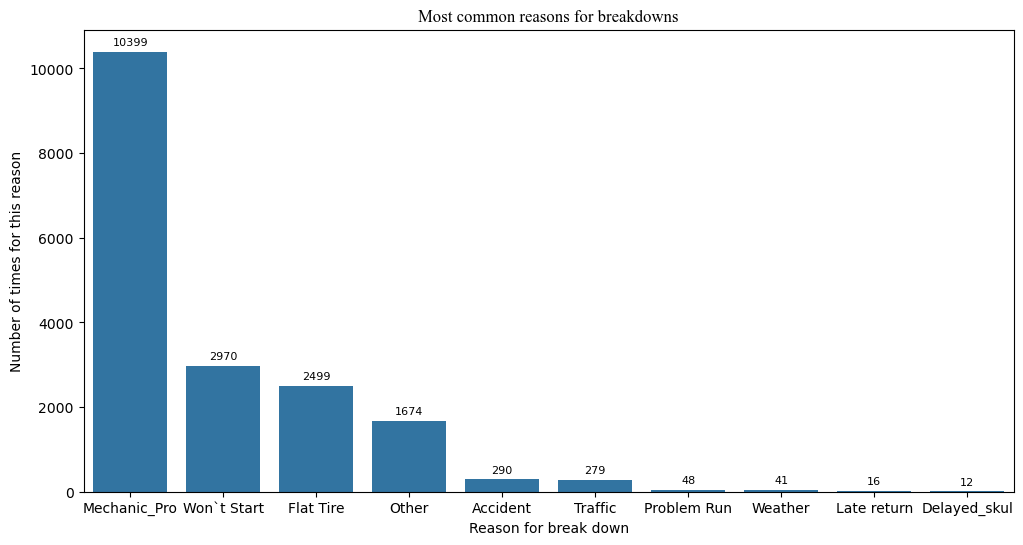

In [108]:
# selecting only break breakdown from this column
Breakdowns=Selected_columns[Selected_columns['Breakdown_or_Running_Late']=='Breakdown'].reset_index()

# counting the reasons by count
Visualize_Breakdowns=Breakdowns['Reason'].value_counts().reset_index()

# converting the results toa dataframe
df1=pd.DataFrame(Visualize_Breakdowns)
# ploting the graph
plt.figure(figsize=(12, 6)) 
plt.title('Most common reasons for breakdowns',fontdict={'fontname':'Times New Roman'})
plt.ylabel('Number of times for this reason')
plt.xlabel('Reason for break down')
sns.barplot(x='Reason',y='count',data=df1)


# Add annotations to the top of the bar
for m in plt.gca().patches:
    height = m.get_height()
    plt.text(m.get_x() + m.get_width()/2., height + 100,  # Adjust vertical offset (100) as needed
            '%d' % int(height),
            ha='center', va='bottom',fontsize=8)

plt.show()

# Inference  

The most common reason for breakdowns is a Mechanic Problem, occurring 10,399 times.
This is more than 3.5 times the frequency of the "Won't Start" issue, which occurred 2,970 times. Following "Won't Start," the next most common reason is a Flat Tire, reported 2,499 times.

# Actionable insight 

Implement mandatory service checks for the buses at least every three months. Conduct research, such as surveys targeting maintenance providers, to identify the specific mechanical problems contributing most to breakdowns. Based on this research, implement targeted measures to mitigate these recurring issues. Additionally, establish pre-trip protocols requiring bus drivers to inspect tires thoroughly before each journey. 

### 1.2 Most common reasons for delays

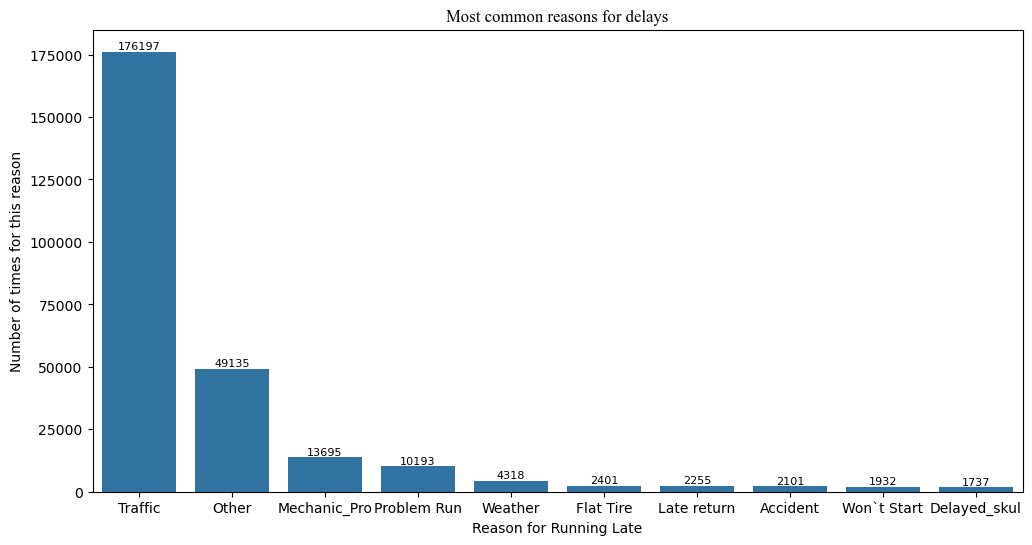

In [114]:
# selecting only break breakdown from this column
Running_Late=Selected_columns[Selected_columns['Breakdown_or_Running_Late']=='Running_Late'].reset_index()

# Counting by reasons
Running_Late_count=Running_Late['Reason'].value_counts().reset_index()

# converting the results to  dataframe
df2=pd.DataFrame(Running_Late_count)
# ploting the graph
plt.figure(figsize=(12, 6)) 
plt.title('Most common reasons for delays',fontdict={'fontname':'Times New Roman'})
plt.ylabel('Number of times for this reason')
plt.xlabel('Reason for Running Late')
sns.barplot(x='Reason',y='count',data=df2)

# Add annotations to the top of the bar
for i in plt.gca().patches:
    height = i.get_height()
    plt.text(i.get_x() + i.get_width()/2., height + 100,  # Adjust vertical offset (100) as needed
            '%d' % int(height),
            ha='center', va='bottom',fontsize=8)

plt.show()

# Inference 

The most common reason for delays is traffic, with 176,197 reported instances.

# Actionable Insights 

Conduct research to identify the underlying causes contributing to the high volume of traffic. There could be many factoes causing this, find the most common things to cause it. 

# 2. How do delay times vary by bus company and borough?-Question

### Process

In [120]:
Selected_columns.head(5)

,Busbreakdown_ID,Reason,How_Long_Delayed,Bus_Company_Name,Boro,Occurred_On,Breakdown_or_Running_Late,Route_Number,Created_On,company_name_standardized
0,1736720,Mechanic_Pro,16-30,PRIDE TRANSPORTATION (SCH AGE),Manhattan,2022-09-01 06:50:00,Breakdown,M772,2022-09-01 07:29:00,PRIDE TRANSPORTATION((SCH AGE))
1,1736736,Traffic,46-60,L & M BUS CORP (A),Nassau County,2022-09-01 08:05:00,Running_Late,N729,2022-09-01 08:31:00,L & M BUS CORP
2,1736748,Traffic,0-15,VAN TRANS LLC (B2192),Westchester,2022-09-02 06:11:00,Running_Late,W203,2022-09-02 06:14:00,VAN TRANS LLC (B2192)
3,1736765,Traffic,31-45,"BORO TRANSIT, INC.",Westchester,2022-09-06 05:50:00,Running_Late,W501,2022-09-06 05:57:00,BORO TRANSIT INC
4,1736837,Traffic,16-30,"G.V.C., LTD.",Bronx,2022-09-06 08:12:00,Running_Late,3,2022-09-06 08:14:00,GVC LTD


## 2.1 How delay times vary by company_name

#### 0-15 minute chategory

In [270]:
# Selecting the columns I would need
company_delay_hours=Selected_columns[['How_Long_Delayed','company_name_standardized']].copy()

# Creating a new dataframe called df: company_delay_hours_df
company_delay_hours_df=pd.DataFrame(company_delay_hours).reset_index()

# Removing extra spaces from the standardized column.
company_delay_hours_df.loc[:, 'company_name_standardized'] = company_delay_hours_df['company_name_standardized'].str.strip() 

# During the standardization of the company_name_standardized column, the value 'Mr.' was unexpectedly present. 
# Since 'Mr.' is not a valid bus company name and likely represents an error in the original data entry, I decided to drop the row below.
company_delay_hours_df.drop(company_delay_hours_df[company_delay_hours_df['company_name_standardized'] == 'Mr'].index, inplace=True)


# APPLYING FILTER 

# selecting short delayes for companies
short_delay_top_companies=company_delay_hours_df.loc[(company_delay_hours_df['How_Long_Delayed']=='0-15'), ['company_name_standardized','How_Long_Delayed']] 

# counting the occurances of a company in a dataset
short_delay_top_companies.loc[:,'BusCompanyCount'] = short_delay_top_companies['company_name_standardized'].map(short_delay_top_companies['company_name_standardized'].value_counts())

# selecting the first 10 rows with the highest occurances of short delays
short_delay_top_companies.drop_duplicates().reset_index().sort_values(by='BusCompanyCount', ascending=False).head(10)


# I selected the top 10  because I wanted to capture that ones that experienced delays the most in this category.

,index,company_name_standardized,How_Long_Delayed,BusCompanyCount
5,117,HOYT TRANSPORTATION CORP,0-15,5821
2,16,PIONEER TRANSPORTATION CORP,0-15,5417
0,2,VAN TRANS LLC (B2192),0-15,4958
3,42,DON THOMAS BUSES INC,0-15,3492
6,148,GVC LTD,0-15,1836
1,13,BORO TRANSIT INC,0-15,1552
4,103,SNT BUS INC,0-15,924
21,1950,L & M BUS CORP,0-15,864
26,3991,ALINA SERVICES CORP,0-15,766
24,3504,CAREFUL BUS SERVICE,0-15,564


## Inference  

Among the reported short-term delays (0-15 minutes), HOYT TRANSPORTATION CORP experienced the highest number of occurrences with 5,821 cases.
PIONEER TRANSPORTATION CORP had the second highest with 5,417 cases, and VAN TRANS LLC (B2192) ranked third with 4,958 reported short-term delays.

#### 16-30 minute category

In [272]:
# Selecting the columns I would need to answer these questions
medium_short_delay_top_companies=df.loc[(df['How_Long_Delayed']=='16-30'),['company_name_standardized','How_Long_Delayed']]

# Counting the occurances of a company in a dataset
medium_short_delay_top_companies.loc[:,'BusCompanyCount'] = medium_short_delay_top_companies['company_name_standardized'].map(medium_short_delay_top_companies['company_name_standardized'].value_counts())

# selecting the first 10 rows with the highest occurances of short delays
medium_short_delay_top_companies.drop_duplicates().reset_index().sort_values(by='BusCompanyCount', ascending=False).head(10)

,index,company_name_standardized,How_Long_Delayed,BusCompanyCount
12,50,EMPIRE CHARTER SERVICE INC,16-30,10020
10,32,ALLIED TRANSIT CORP,16-30,8540
2,5,PIONEER TRANSPORTATION CORP,16-30,8126
1,4,GVC LTD,16-30,7733
15,66,BORO TRANSIT INC,16-30,6933
5,19,HOYT TRANSPORTATION CORP,16-30,5882
9,31,LEESEL TRANSPORTATION CORP,16-30,4986
17,83,VAN TRANS LLC (B2192),16-30,4414
6,26,L & M BUS CORP,16-30,4301
14,56,EMPIRE STATE BUS CORP,16-30,4025


## Inference 

In the 16-30 minute delay category, EMPIRE CHARTER SERVICE INC. reported the highest frequency with 10,020 instances. ALLIED TRANSIT CORP experienced the second most delays in this range, with 8,540 reported cases. Notably, PIONEER TRANSPORTATION CORP appears in the top three again with 8,126 reported delays in the 16-30 minute window.

PIONEER TRANSPORTATION CORP's reported delays in the 16-30 minute category (8,126 cases) show a significant increase of approximately 50% compared to their reported short delays of 0-15 minutes (5,417 cases). This substantial rise warrants further investigation into the factors contributing to these medium-short delays for PIONEER TRANSPORTATION CORP.

## 31-45 minute category

In [280]:
# Selecting the columns I would need to answer this question.
medium_delay_top_companies=df.loc[(df['How_Long_Delayed']=='31-45'),['company_name_standardized','How_Long_Delayed']].copy()

# counting the occurances of a company in a dataset
medium_delay_top_companies.loc[:,'BusCompanyCount'] = medium_delay_top_companies['company_name_standardized'].map(medium_delay_top_companies['company_name_standardized'].value_counts())

# selecting the first 10 rows with the highest occurances of short delays
medium_delay_top_companies.drop_duplicates().reset_index().sort_values(by='BusCompanyCount', ascending=False).head(10)

,index,company_name_standardized,How_Long_Delayed,BusCompanyCount
3,12,LEESEL TRANSPORTATION CORP,31-45,16053
16,198,NYC SCHOOL BUS UMBRELLA SERVICES,31-45,9544
1,9,RELIANT TRANSPORTATION INC (B2321),31-45,9460
13,143,PIONEER TRANSPORTATION CORP,31-45,7960
0,3,BORO TRANSIT INC,31-45,4849
8,48,L & M BUS CORP,31-45,3293
7,43,PRIDE TRANSPORTATION((SCH AGE)),31-45,3166
4,14,GVC LTD,31-45,2133
5,15,CONSOLIDATED BUS TRANS INC,31-45,1892
22,320,PHILLIPS BUS SERVICE,31-45,1513


##  Inference 

In the 31-45 minute delay category, LEESEL TRANSPORTATION CORP reported the highest number of incidents (16,053), which is approximately 68.2% more than NYC SCHOOL BUS UMBRELLA SERVICES (9,544 incidents) and about 69.7% more than RELIANT TRANSPORTATION INC (B2321) (9,460 incidents).

Notably, PIONEER TRANSPORTATION CORP appears again in this category at the fourth position with 7,960 reported cases. This marks their third appearance across the analyzed delay categories, having ranked second in the 0-15 minute delays and third in the 16-30 minute delays.

## 46-60 minute category

In [282]:
# Selecting the columns I would need to answer questions.
medium_long_delay_top_companies=df.loc[(df['How_Long_Delayed']=='46-60'),['company_name_standardized','How_Long_Delayed']]

# Counting the occurances of a company in a dataset
medium_long_delay_top_companies.loc[:,'BusCompanyCount'] = medium_long_delay_top_companies['company_name_standardized'].map(medium_long_delay_top_companies['company_name_standardized'].value_counts())

# selecting the first 10 rows with the highest occurances of short delays
medium_long_delay_top_companies.drop_duplicates().reset_index().sort_values(by='BusCompanyCount', ascending=False).head(10)

,index,company_name_standardized,How_Long_Delayed,BusCompanyCount
2,20,LEESEL TRANSPORTATION CORP,46-60,17675
16,232,PIONEER TRANSPORTATION CORP,46-60,5631
14,217,PRIDE TRANSPORTATION((SCH AGE)),46-60,5383
0,1,L & M BUS CORP,46-60,4376
12,191,BORO TRANSIT INC,46-60,2647
29,1909,NYC SCHOOL BUS UMBRELLA SERVICES,46-60,1991
5,51,LITTLE RICHIE BUS SERVICE,46-60,1320
6,54,LORINDA ENTERPRISES LTD,46-60,1315
11,137,LOGAN BUS COMPANY INC,46-60,1182
4,34,DON THOMAS BUSES INC,46-60,759


## Inference 

In the 46-60 minute delay category, LEESEL TRANSPORTATION CORP shows the highest number of reported delays with 17,675 incidents, marking their second time as the company with the most delays across the analyzed categories. Following LEESEL TRANSPORTATION CORP is PIONEER TRANSPORTATION CORP with 5,631 reported cases, their fourth appearance in the top rankings for delay frequency. PRIDE TRANSPORTATION (SCH AGE) ranks third with 5,383 reported delays in this 46-60 minute window.

The data suggests a trend where LEESEL TRANSPORTATION CORP experiences a particularly high number of incidents as the duration of the delay increases.

## 61-90 minute category

In [323]:
# Selecting the columns I would need to answer this question.
long_delay_top_companies=df.loc[(df['How_Long_Delayed']=='61-90'),['company_name_standardized','How_Long_Delayed']].copy()

# counting the occurances of a company in a datase.
long_delay_top_companies.loc[:,'BusCompanyCount'] = long_delay_top_companies['company_name_standardized'].map(long_delay_top_companies['company_name_standardized'].value_counts())

# selecting the first 10 rows with the highest occurances of short delays. 
long_delay_top_companies.drop_duplicates().reset_index().sort_values(by='BusCompanyCount', ascending=False).head(10)

,index,company_name_standardized,How_Long_Delayed,BusCompanyCount
0,6,PRIDE TRANSPORTATION((SCH AGE)),61-90,9489
3,90,LEESEL TRANSPORTATION CORP,61-90,5797
5,114,L & M BUS CORP,61-90,4012
9,292,LITTLE RICHIE BUS SERVICE,61-90,2006
7,131,LOGAN BUS COMPANY INC,61-90,1307
4,104,MAR-CAN TRANSPORT CO INC (B2192),61-90,1130
13,1039,LORINDA ENTERPRISES LTD,61-90,1027
1,33,SELBY TRANSPORTATION,61-90,860
2,37,GVC LTD,61-90,429
31,43826,NYC SCHOOL BUS UMBRELLA SERVICES,61-90,401


## Inference  

In the long delay category (61-90 minutes), PRIDE TRANSPORTATION (SCH AGE) reported the highest number of incidents with 9,489 cases. LEESEL TRANSPORTATION CORP follows with 5,797 reported delays in this duration, marking their third appearance among the top companies for longer delays. L & M BUS CORP reported 4,012 incidents of delays in the 61-90 minute range.

Notably, L & M BUS CORP has shown a relatively consistent number of reported delays across the different delay time categories analyzed so far. 

### Overall


**Consistent Performers Across Delay Durations:**

PIONEER TRANSPORTATION CORP and LEESEL TRANSPORTATION CORP have consistently appeared among the top companies experiencing delays across the short (0-15 minutes), medium-short (16-30 minutes), and medium (31-45 minutes) delay categories.

**Top Performers in Common Delay Categories:**

Several companies frequently ranked within the top three for the most common delay categories. These include: EMPIRE CHARTER SERVICE INC, ALLIED TRANSIT CORP, HOYT TRANSPORTATION CORP, VAN TRANS LLC (B2192), NYC SCHOOL BUS UMBRELLA SERVICES, RELIANT TRANSPORTATION INC (B2321), PRIDE TRANSPORTATION (SCH AGE), L & M BUS CORP, and GVC LTD. Further investigation is warranted to understand the specific factors contributing to these recurring delays for these companies, considering both the reasons identified in earlier visualizations (like traffic, mechanical issues) and other potential factors.

**Actionable Insight:**

Conduct surveys targeting bus drivers from the consistently top-ranking companies (e.g., PIONEER TRANSPORTATION CORP, LEESEL TRANSPORTATION CORP, and others frequently in the top three) to gather qualitative data on the primary causes of their delays. This should explore whether traffic is the dominant factor or if other issues, such as operational challenges, maintenance problems, or scheduling conflicts, play a significant role. Further quantitative research should then focus on the specific factors identified to understand why certain companies experience more frequent and longer delays.

# 2.2 How do delay times vary by borough ? - Question

### Process

In [286]:
#delayTimeByBoro=Selected_columns[['Boro'].value_counts(),['How_Long_Delayed','Boro']].reset_index()
delayTimeByBoro_1=Selected_columns[['How_Long_Delayed','Boro']]
delayTimeByBoro_2=pd.DataFrame(delayTimeByBoro_1)

# Grouping by these two columns:['Boro','How_Long_Delayed']
Grouped=delayTimeByBoro_2.groupby(['Boro','How_Long_Delayed']).size().reset_index(name='countOcurrances')
Grouped.head()

,Boro,How_Long_Delayed,countOcurrances
0,All Boroughs,0-15,226
1,All Boroughs,16-30,513
2,All Boroughs,31-45,250
3,All Boroughs,46-60,82
4,All Boroughs,61-90,48


### Creating a new dataframe where there is no "All Boroughs" - this column is not going to be needed.

In [289]:
All_Borough_dropped= Grouped[Grouped['Boro'] != 'All Boroughs'] # drop all boroughs, it is not necessary in here

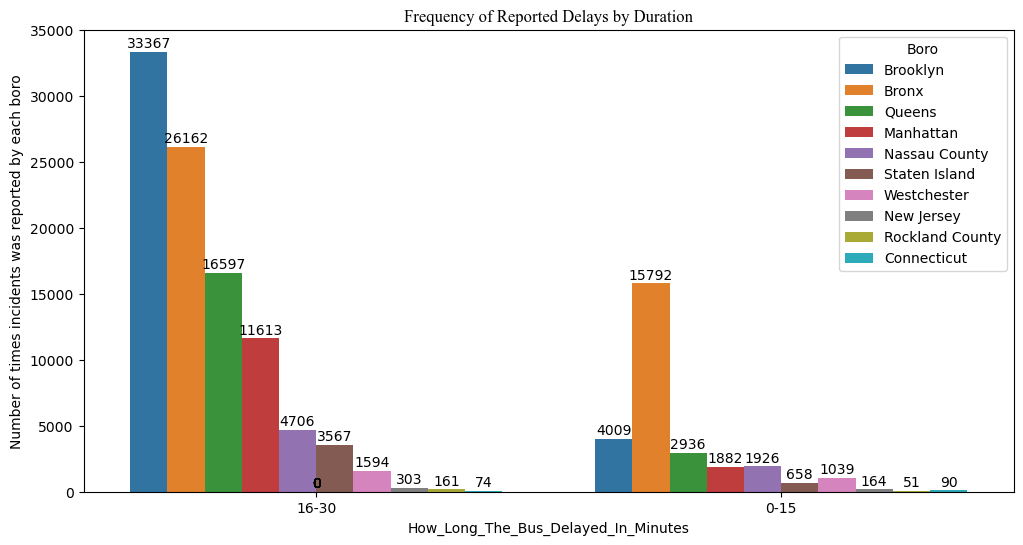

In [291]:
# locate the boros that have short_and_medium_delay
short_and_medium_delay=All_Borough_dropped.loc[All_Borough_dropped['How_Long_Delayed'].isin(["0-15", "16-30"]),
    ['Boro', 'countOcurrances','How_Long_Delayed']
]
short_and_medium_delay_df=pd.DataFrame(short_and_medium_delay).sort_values(by="countOcurrances",ascending=False)

# ploting the graph
plt.figure(figsize=(12, 6))
plt.title('Frequency of Reported Delays by Duration',fontdict={'fontname':'Times New Roman'})
plt.ylabel('Number of times incidents was reported by each boro')
plt.xlabel('How_Long_The_Bus_Delayed_In_Minutes')
sns.barplot(x='How_Long_Delayed',y='countOcurrances',hue='Boro',data=short_and_medium_delay_df)

# adding labels at the top of the bar
for p in plt.gca().patches:
    height = p.get_height()
    plt.text(p.get_x() + p.get_width()/2., height + 100,  # Adjust vertical offset (100) as needed
            '%d' % int(height),
            ha='center', va='bottom')

plt.show()

### Inference 

0-15 Minute Delays:

Among the reported short delays (0-15 minutes), the Bronx exhibits the highest number of incidents with 15,792 cases. The frequency of these short delays in the Bronx is approximately 3.86 times that of Brooklyn (4,089 cases).

16-30 Minute Delays:

For delays in the 16-30 minute range, Brooklyn reports the highest number of incidents with 33,368 cases. The Bronx follows with 26,161 reported cases, and Queens ranks third with 16,597 cases. Manhattan also shows a significant number of delays in this category with 11,613 reported cases.

## Medium_long_delay : ["31-45", "46-60"] minutes

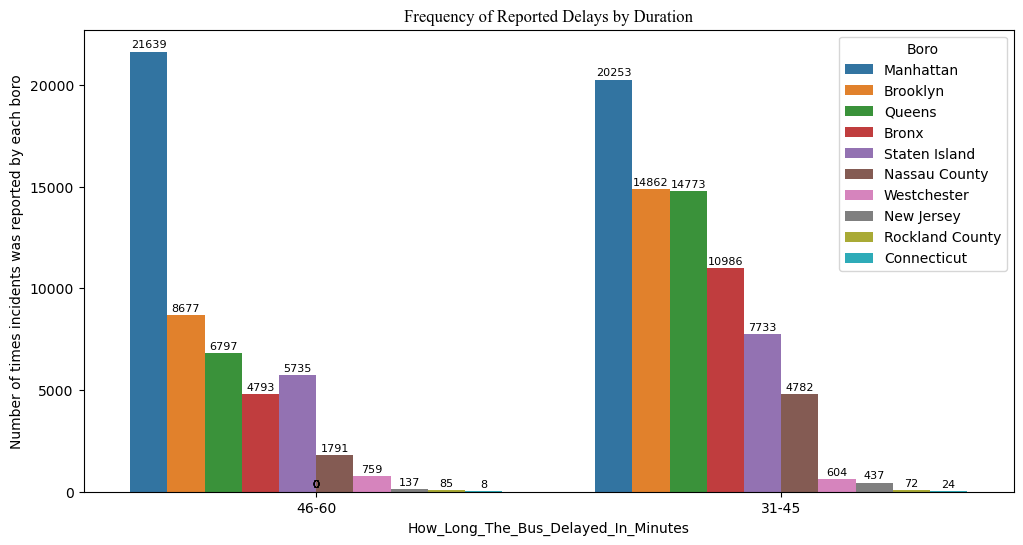

In [296]:
medium_long_delay=All_Borough_dropped.loc[  # locate the boros that have short_and_medium_delay
    All_Borough_dropped['How_Long_Delayed'].isin(["31-45", "46-60"]),
    ['Boro', 'countOcurrances','How_Long_Delayed']
]
medium_long_delay_df=pd.DataFrame(medium_long_delay).sort_values(by='countOcurrances',ascending=False)

# plotting the graph
plt.figure(figsize=(12, 6))
plt.title('Frequency of Reported Delays by Duration',fontdict={'fontname':'Times New Roman'})
plt.ylabel('Number of times incidents was reported by each boro')
plt.xlabel('How_Long_The_Bus_Delayed_In_Minutes')
sns.barplot(x='How_Long_Delayed',y='countOcurrances',hue='Boro',data=medium_long_delay_df)

# Add annotations to the top of the bar
for p in plt.gca().patches:
    height = p.get_height()
    plt.text(p.get_x() + p.get_width()/2., height + 100,  # Adjust vertical offset (100) as needed
            '%d' % int(height),
            ha='center', va='bottom',fontsize=8)
    
plt.show()

### Inference 

31-45 Minute Delays:

Manhattan reports the highest number of incidents for delays in the 31-45 minute range with 20,253 cases. Brooklyn follows with 14,862 reported cases, and Queens shows a similar number with 14,773 cases.

46-60 Minute Delays:

For the 46-60 minute delay category, Manhattan again exhibits the highest number of reported incidents with 21,639 cases. This is more than double the number of reported cases in Brooklyn (8,677 cases), which has the second highest frequency for this delay duration.

### Longest_delay_time : ["61-90"] minutes

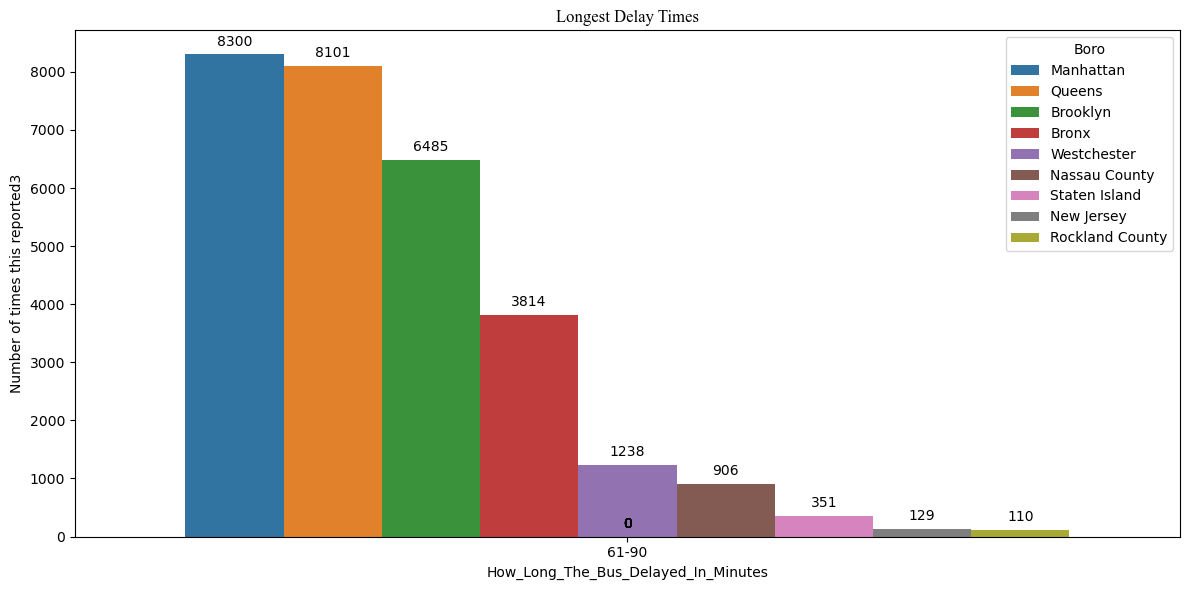

In [301]:
Longest_delay_time=All_Borough_dropped.loc[  # locate the boros that have short_and_medium_delay
    All_Borough_dropped['How_Long_Delayed'].isin(["61-90"]),
    ['Boro', 'countOcurrances','How_Long_Delayed']
]
Longest_delay_time_df=pd.DataFrame(Longest_delay_time).sort_values(by='countOcurrances',ascending=False)

# plotting the graph
plt.figure(figsize=(12, 6))
plt.title('Longest Delay Times',fontdict={'fontname':'Times New Roman'})
plt.ylabel('Number of times this reported3')
plt.xlabel('How_Long_The_Bus_Delayed_In_Minutes')
ax=sns.barplot(x='How_Long_Delayed',y='countOcurrances',hue='Boro',data=Longest_delay_time_df)


# Add annotations to the top of the bars
for p in plt.gca().patches:
    height = p.get_height()
    plt.text(p.get_x() + p.get_width()/2., height + 100,  # Adjust vertical offset (100) as needed
            '%d' % int(height),
            ha='center', va='bottom')
    
num_categories = len(Longest_delay_time_df['How_Long_Delayed'].unique())
ax.set_xlim([-0.5, num_categories - 0.5])
plt.tight_layout()
plt.show()

### Inference 

 For the longest delay category (61-90 minutes), Manhattan reports the highest number of incidents with 8,300 cases, closely followed by Queens with 8,101 reported cases. Brooklyn also shows a significant number of long delays with 6,485 reported cases.


# Overall 

Given that there is consistently high number of reported delays in Manhattan, Brooklyn, and Queens across various durations, and the particularly high number of short delays in the Bronx, targeted investigations should be conducted within these boroughs. These investigations should aim to identify the primary causes of delays specific to each borough and delay duration. For instance:

In the Bronx (for short delays): Focus on identifying localized bottlenecks, traffic patterns, or operational issues that might cause frequent brief delays.
In Manhattan (for longer delays): Investigate potential causes for prolonged disruptions, such as traffic congestion in key areas, infrastructure limitations, or specific operational challenges.
In Brooklyn and Queens (across all durations): Conduct a broader analysis to understand the systemic factors contributing to the consistently high number of delays.
Understanding the borough-specific and duration-specific patterns of delays will allow for the development of more effective and targeted interventions to improve transportation efficiency

# 3. Is there a correlation between specific days of the week and the frequency of breakdowns or delays?

In [307]:
# Process

In [309]:
# Steps
# Extract the day from the time(monday/tuesday....) and create the column called days_of_the_week. --see if you can aggregate by days_of_the_week
# Create the numerical representation for days_of_the_week(numerical).# data encoding
# find the relationship between these numerical columns/ use a chi-square 

### Is there a correlation between specific days of the week and the frequency of breakdowns

In [312]:
Selected_columns.dropna(subset='Occurred_On',inplace=True)  # dropping row where there are nulls in the 'Occured_On' column.

In [314]:
Selected_columns['Day_of_week']=Selected_columns['Occurred_On'].dt.day_name() # Extracting the day from the column "Occured_On" and putting it into a new column "Day_of_week". 

#### Create the numerical representation for days_of_the_week(numerical). # Data encoding

In [317]:
# Creating a dictionry to represent the days of the week in numerical terms.
Day_Mapping = {
'Monday':1,
'Tuesday':2,
'Wednesday':3,
'Thursday':4,
'Friday':5,
'Saturday':6,
'Sunday':7
}
# creating a column to represent the weekdays numerically
Selected_columns['Numeric_Days_of_week']=Selected_columns['Day_of_week'].map(Day_Mapping).astype(int)

## Using Chi-quare to find the relationship

In [320]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency



# --- 1. Selecting the columns I would need for to answer questions -------------
sub = Selected_columns[['Numeric_Days_of_week', 'Breakdown_or_Running_Late']]

# --- 2. contingency table: Outcome (rows) × Weekday (cols)
table = pd.crosstab(
    sub['Breakdown_or_Running_Late'],
    sub['Numeric_Days_of_week'],
    dropna=False
)



# --- 3. χ² test of independence --------------------------
chi2, p, dof, expected = chi2_contingency(table)

# --- 4. Cramer's V  --------------------------------------
n = table.to_numpy().sum()
v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))


print("\n=== Chi-square test ===")
print(f"χ²  = {chi2:,.2f}  (df = {dof})")
print(f"p-value = {p:.3g}")


print("\n=== Cramer’s V ===")
print(f"V = {v:.3f}  (0 =no association, 1 = perfect)")

# Optional: show table
print("\nContingency table (observed counts):")
display(table)



=== Chi-square test ===
χ²  = 46.37  (df = 5)
p-value = 7.65e-09

=== Cramer’s V ===
V = 0.013  (0 =no association, 1 = perfect)

Contingency table (observed counts):


Numeric_Days_of_week,1,2,3,4,5,7
Breakdown_or_Running_Late,,,,,,
Breakdown,4146,3619,3573,3572,3318,0
Running_Late,54667,52332,53589,53862,49512,1


## Inference 

While the Chi-square test indicates a statistically significant association (p-value = 7.65×10−9) between the day of the week and the frequency of breakdowns or delays, the strength of this association is very weak (Cramer's V = 0.013). 

This suggests that although the frequency of breakdowns and delays is not entirely independent of the day of the week, the day of the week itself is not a significant predictor or primary factor influencing these events.

# 4. Are certain bus routes more prone to breakdowns or delays than others?

### 4.1 Are certain bus routes more prone to delays than others? 

In [197]:
# Route_Number, Breakdown_or_Running_Late

In [330]:
# Selecting the columns
Needed_Running_Late=Selected_columns[['Breakdown_or_Running_Late','Route_Number']].copy()

# Converting rout_numbers to be of type string
Needed_Running_Late.loc[:,'Route_Number'] = Needed_Running_Late['Route_Number'].astype(str) 


# selecting breakdowns. # .copy-creating a copy  of a dataframe to avoid warning.
Runnnging_late=Needed_Running_Late[Needed_Running_Late['Breakdown_or_Running_Late']=='Running_Late'].copy() 


# couting the number of unique values
Runnnging_late['Number_count']=Runnnging_late['Route_Number'].map(Runnnging_late['Route_Number'].value_counts())


# sorting the values in discending order so that i can find the highest
Needed_Running_Late_sorted=Runnnging_late.sort_values(by='Number_count',ascending=False)

In [332]:
Needed_Running_Late_sorted.drop_duplicates().head(10)

,Breakdown_or_Running_Late,Route_Number,Number_count
135975,Running_Late,2,1155
253582,Running_Late,1,693
45217,Running_Late,3,397
52620,Running_Late,N109,371
236974,Running_Late,K013,349
18494,Running_Late,N081,329
32995,Running_Late,N450,325
171440,Running_Late,N131,290
125207,Running_Late,N511,287
82334,Running_Late,K025,279


## Inference  

There are 1155 reported times route 2 had delays, followed by route 1 with 693 times this was reported.
Other route seems to be around the same count of occurances, there nothing out of ordinary.

### 4.2 Are certain bus routes more prone to breakdowns than others? 

In [207]:
Needed_Breaking_down=Selected_columns[['Breakdown_or_Running_Late','Route_Number']]

# Converting rout_numbers to be of type string
Needed_Breaking_down.loc[:,'Route_Number'] = Needed_Breaking_down['Route_Number'].astype(str) 


# selecting breakdowns
Needed_Breaking_down=Needed_Breaking_down[Needed_Breaking_down['Breakdown_or_Running_Late']=='Breakdown'] 


# couting the number of unique values
Needed_Breaking_down['Number_count']=Needed_Breaking_down['Route_Number'].map(Needed_Breaking_down['Route_Number'].value_counts())


# sorting the values in discending order so that i can find the highest
Needed_Breaking_down_sorted=Needed_Breaking_down.sort_values(by='Number_count',ascending=False)

In [209]:
Needed_Breaking_down_sorted.drop_duplicates().head(10)

,Breakdown_or_Running_Late,Route_Number,Number_count
114115,Breakdown,X616,31
8954,Breakdown,X593,28
170761,Breakdown,Y215,26
263029,Breakdown,Y205,25
21152,Breakdown,K8454,24
10041,Breakdown,X040,23
108339,Breakdown,X541,23
7770,Breakdown,X888,22
118252,Breakdown,X905,22
230481,Breakdown,Y107,22


## Inference  

These are the most common routes where breakdowns happen, at number 1 "X616" with the highest number of breakdowns exhiting 31 reported times 31.
Another route that is prone to breakdowns is "X593" at number two with 28 reported times and there is also Y215 with 26 reported times.

As such as breakdowns are common the route number doesnt seem to have very impact on the breakdowns of buses

## Overall


Crucially, there is no direct overlap between the top 10 routes most prone to delays and the top 10 routes most prone to breakdowns. 
This indicates that the underlying issues contributing to "running late" incidents are likely distinct from those causing "breakdowns."
This suggests different operational challenges and root causes are at play for each type of incident.


## Actionable Insights 


### For Delay-Prone Routes (e.g., Route 2, Route 1):

Traffic Management & Scheduling Review: Conduct a detailed analysis of traffic patterns, road conditions, and existing schedules on these routes during peak hours. Evaluate if current schedules are realistic, considering typical traffic flow.

Route Optimization: Explore minor route adjustments or the implementation of real-time traffic monitoring systems to help drivers navigate congestion more efficiently.

Driver Feedback & Training: Gather qualitative insights from drivers operating on these routes regarding specific bottlenecks or operational challenges. Provide targeted training on efficient driving techniques in congested environments.


### For Breakdown-Prone Routes (e.g., Route X616, Route X593):

Enhanced Vehicle Maintenance: Implement a more rigorous maintenance schedule or specific diagnostic checks for buses assigned to these routes. Investigate if particular bus models or older vehicles are disproportionately assigned to these routes.

Route Condition Assessment: Assess the physical conditions of these routes (e.g., rough roads, frequent stops, steep inclines) that might put extra stress on vehicles.
Fleet Management Review: Analyze the age and maintenance history of buses predominantly used on these breakdown-prone routes. Consider re-allocating newer or more robust vehicles if feasible.

# Cleaning data for the last two questions 5 and 6.

### Selecting columns 

In [216]:
Notified=Bus[['Busbreakdown_ID','How_Long_Delayed','Breakdown_or_Running_Late','Number_Of_Students_On_The_Bus','Has_Contractor_Notified_Schools','Has_Contractor_Notified_Parents','Have_You_Alerted_OPT']]

In [218]:
# Creating an a copy of the dataframe so that I dont have any warning issues.
Notified = Bus[['Busbreakdown_ID','How_Long_Delayed','Breakdown_or_Running_Late','Number_Of_Students_On_The_Bus','Has_Contractor_Notified_Schools','Has_Contractor_Notified_Parents','Have_You_Alerted_OPT']].copy()

# Step-by-step cleaning without triggering FutureWarning
cleaned_col = Notified['Number_Of_Students_On_The_Bus'].astype(str).str.strip() # Convert to string and stripping extra spaces 
cleaned_col = pd.to_numeric(cleaned_col, errors='coerce').fillna(0).astype(int) # converting column back to a number, filling NaN with 0

# Now assign the cleaned column
Notified['Number_Of_Students_On_The_Bus'] = cleaned_col

#### Cleaning the column called "How_Long_Delayed"

In [221]:
# converting the data type
Notified.loc[:,'How_Long_Delayed'] = Notified['How_Long_Delayed'].astype(str) 

# using lambda expression to specify the last 3 characters:min and remove them
Notified.loc[:,'How_Long_Delayed'] = Notified['How_Long_Delayed'].apply(lambda x: x[:-3] if x.endswith('Min') else x) 

# replacing non digits values with space
Notified.loc[:,'How_Long_Delayed'] = Notified['How_Long_Delayed'].str.replace(r"\D", " ", regex=True) 

# replacing the space between numbers with a "-"
Notified.loc[:,'How_Long_Delayed'] = Notified['How_Long_Delayed'].str.replace(r"(?<=\d) (?=\d)","-",regex=True)

# Stripping the column[removing the extra spaces]
Notified.loc[:,'How_Long_Delayed'] = Notified['How_Long_Delayed'].str.strip() 

In [223]:
Notified.head()

,Busbreakdown_ID,How_Long_Delayed,Breakdown_or_Running_Late,Number_Of_Students_On_The_Bus,Has_Contractor_Notified_Schools,Has_Contractor_Notified_Parents,Have_You_Alerted_OPT
0,1736720,16-30,Breakdown,0,No,No,No
1,1736736,46-60,Running Late,3,Yes,Yes,No
2,1736748,0-15,Running Late,0,Yes,Yes,Yes
3,1736765,31-45,Running Late,0,No,Yes,No
4,1736837,16-30,Running Late,3,Yes,Yes,No


# 5. Is there a relationship between the number of students on the bus and the  likelihood or severity of a delay or breakdown ?

In [227]:
#Relationship=Notified['Breakdown_or_Running_Late','Number_Of_Students_On_The_Bus']

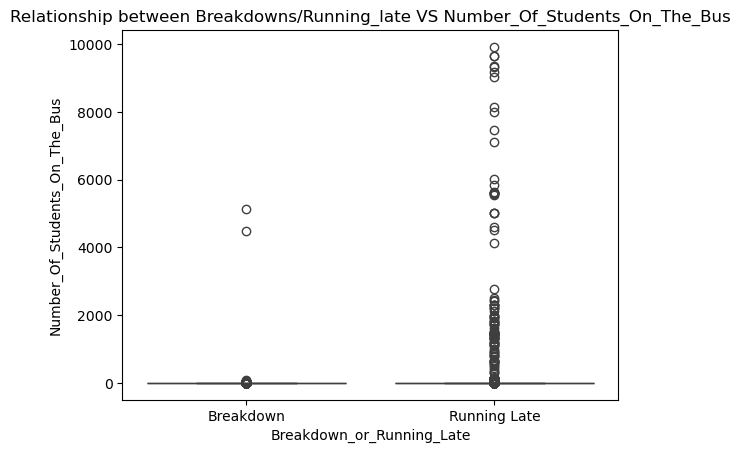

In [229]:
sns.boxplot(x='Breakdown_or_Running_Late',y='Number_Of_Students_On_The_Bus',data=Notified)
plt.title("Relationship between Breakdowns/Running_late VS Number_Of_Students_On_The_Bus")
plt.show()

## Inference 

In the case of Breakdown events, most data points fall within a very narrow range, with the median and entire interquartile range concentrated around zero students. This indicates that breakdowns typically occurred when there were very few or no students on the bus.

In contrast, for Running Late events, the number of students on the bus shows much greater variability. There are many values significantly above the upper whisker, suggesting frequent delays even when the bus was carrying a large number of students. This implies that buses tend to run late more often when more students are on board.



 # 6. Has_Contractor_Notified_Schools, Has_Contractor_Notified_Parents, and Have_You_Alerted_OPT,How_Long_Delayed

In [234]:
Notified.head()

,Busbreakdown_ID,How_Long_Delayed,Breakdown_or_Running_Late,Number_Of_Students_On_The_Bus,Has_Contractor_Notified_Schools,Has_Contractor_Notified_Parents,Have_You_Alerted_OPT
0,1736720,16-30,Breakdown,0,No,No,No
1,1736736,46-60,Running Late,3,Yes,Yes,No
2,1736748,0-15,Running Late,0,Yes,Yes,Yes
3,1736765,31-45,Running Late,0,No,Yes,No
4,1736837,16-30,Running Late,3,Yes,Yes,No


In [236]:
# Thinking of counting number of occurances for "yes" divide by the occurances of "No" to get the percentage of the time the contractor notified school in comparison to not.

In [238]:
# For 'Has_Contractor_Notified_Schools'
school_notifications = Notified['Has_Contractor_Notified_Schools'].value_counts(normalize=True) * 100   # getting the propotion of yes and no to the column
print("Percentage of Contractor Notifying Schools:")
print(school_notifications)

Percentage of Contractor Notifying Schools:
Has_Contractor_Notified_Schools
Yes    73.279186
No     26.720814
Name: proportion, dtype: float64


## Inference  

The contractor notified the school in approximately 73% of the recorded incidents of breakdowns or delays,
and did not notify the school in approximately 27% of those incidents.


## Actionable Insights  

The 27% of missed school notifications highlights a key communication gap, to improve this:

Standardize & Enforce Protocols: Review and clarify contractor notification protocols for schools. Ensure these are mandatory and consistently followed for all relevant incidents.

Improve Training & Accountability: Provide targeted training to contractor staff on proper notification procedures. Establish clear accountability for missed alerts and implement a feedback system for continuous improvement.


### Has_Contractor_Notified_Parents

In [244]:
# For 'Has_Contractor_Notified_Parents'

# getting the propotion of yes and no to the column
print("\nPercentage of Contractor Notifying Parents:")
parent_notifications = Notified['Has_Contractor_Notified_Parents'].value_counts(normalize=True) * 100   # getting the propotion of yes and no to the column
print("\nPercentage of Contractor Notifying Parents:")
print(parent_notifications)


Percentage of Contractor Notifying Parents:

Percentage of Contractor Notifying Parents:
Has_Contractor_Notified_Parents
Yes    65.13544
No     34.86456
Name: proportion, dtype: float64


## Inference
The contractor notified parents in approximately 65% of the recorded incidents of breakdowns or delays, 
and did not notify parents in approximately 35% of those incidents


 ## Actionable Insight
 Actionable Insights (Parent Notifications)
The 35% of incidents where parents were not notified is a significant gap in communication, potentially leading to parent frustration and concern. To address this:

Enhance Parent Communication Channels: Review and potentially expand the methods used to notify parents (e.g., automated SMS/app alerts, clearer protocols for phone calls). Ensure information is timely and easily accessible.

Clarify Notification Triggers: Define clear, standardized criteria for when parents must be notified (e.g., all breakdowns, delays exceeding a specific duration). Ensure these triggers are well-understood by all contractor and dispatch staff.

Collect Parent Feedback: Implement a system to gather feedback from parents regarding notification effectiveness. This can help identify specific pain points and refine communication strategies.

### Have_You_Alerted_OPT ?

In [250]:
# getting the propotion of yes and no to the column
opt_alerts = Notified['Have_You_Alerted_OPT'].value_counts(normalize=True) * 100 
#print("\nPercentage for alerted OPT:")
print("\nPercentage of 'Have You Alerted OPT':")
print()
print(opt_alerts)


Percentage of 'Have You Alerted OPT':

Have_You_Alerted_OPT
No     82.201834
Yes    17.798166
Name: proportion, dtype: float64


## Inference 
Approximately 82 percent of the times the OTP was never alerted alerted and 17 percent of the times, it was alerted.

## Actionable Insights 

Prioritize OPT Notification: Immediately address the extremely low (18%) OPT notification rate. Implement clear, mandatory protocols and explore automated alert systems to ensure OPT is informed of critical incidents.

Strengthen School & Parent Communication: Standardize and clarify existing notification protocols for schools and parents.

Provide training to staff on the importance of timely updates, and explore diverse communication channels (e.g., SMS, app alerts) for parents.

Monitor & Enforce Compliance: Establish robust monitoring mechanisms and feedback loops to track notification adherence. This will identify ongoing issues and hold contractors accountable for improving communication across all stakeholders.

## How long delailed

In [255]:
How_Long_Delayed_Percentage=Notified['How_Long_Delayed'].value_counts(normalize=True)*100
print("\nPercentage of how long delayed per time range")
print()
print(How_Long_Delayed_Percentage)


Percentage of how long delayed per time range

How_Long_Delayed
16-30    34.961303
31-45    26.498271
46-60    17.896680
61-90    10.447497
0-15     10.196249
Name: proportion, dtype: float64


## Inference 

Approximately 34 percent of the times, the buses delay by 16 to 30 minues,
26 percent of the times the buses delay by 31 to 34 minutes, 17 percent of the times the buses delay by 46 to 60 minutes,
10 percent of the times the buses delay 61 to 90 minutes 
and approximately 10 percent of the times the buses were delayed by 0 to 15 minutes.                        
                        

## Actionable Insights 

The extremely low notification rates for 46-60 and 61-90 minute delays are a critical operational and customer service issue.
Urgent action is required to ensure relevant stakeholders are informed during prolonged disruptions:

Mandatory Protocol Enforcement for Extended Delays: Implement and rigorously enforce clear, non-negotiable protocols for notification when delays exceed a certain threshold (e.g., 30 minutes, 45 minutes)

These protocols must specify who (e.g., contractors, dispatchers) notifies whom (e.g., schools, parents, OPT) and how.
Root Cause Investigation of Missed Notifications: Conduct a deep dive into the 79-82% of incidents in these categories where notifications were not sent.

Determine the specific reasons: Are staff unaware of the protocol for long delays? Is there a technical barrier? Is there a lack of urgency or perceived necessity?

Automated Alert System Integration: Explore or develop automated alert systems that trigger notifications to relevant parties once a delay duration crosses a predefined threshold. This would reduce manual oversight and ensure consistency.
Impact Assessment & Training: Highlight the severe negative impact of uncommunicated long delays (e.g., student safety concerns, parent frustration, logistical chaos for schools). Provide targeted training to all personnel on the critical importance of these notifications for public trust and operational efficiency.

In [390]:
# by Mpumelelo Sithole